<a href="https://colab.research.google.com/github/hershiaytoda/walmart-hurricane-project/blob/main/2026_10_30_%E2%80%94_Midterm_Progress_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

In [ ]:
!git clone https://github.com/hershiaytoda/walmart-hurricane-project.git
%cd /content/walmart-hurricane-project
!ls
!ls data
import pandas as pd
transactions = pd.read_csv("data/walmart_transactions.csv")
transactions.head()

Cloning into 'walmart-hurricane-project'...
remote: Enumerating objects: 96, done.
remote: Counting objects: 100% (96/96), done.
remote: Compressing objects: 100% (86/86), done.
remote: Total 96 (delta 30), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (96/96), 654.25 KiB | 4.78 MiB/s, done.
Resolving deltas: 100% (30/30), done.
/content/walmart-hurricane-project
CHARTER.md  data  notebook  notebooks  README.md  walmart-hurricane-project
distribution_centers.csv  product_catalog.csv  walmart_transactions.csv
inventory_and_sales.db	  store_locations.csv


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [ ]:
# TODO: the numbers

import pandas as pd
import matplotlib.pyplot as plt


raw = pd.read_csv("data/walmart_transactions.csv", dtype=str)
tx = raw.drop_duplicates().copy()                                    # exact duplicate rows
tx["timestamp"] = pd.to_datetime(tx["timestamp"].str.strip(), format="mixed", errors="coerce")
n_no_ts = int(tx["timestamp"].isna().sum())
tx = tx.dropna(subset=["timestamp"]).copy()                          # no timestamp = cannot be placed on a day
tx["quantity"] = pd.to_numeric(tx["quantity"], errors="coerce")
tx["unit_price"] = pd.to_numeric(tx["unit_price"].str.replace(r"[$,\s]", "", regex=True), errors="coerce")
n_neg = int((tx["quantity"] < 0).sum())
tx = tx[tx["quantity"] > 0].copy()                                   # sales only (negative quantity = returns)
tx["revenue"] = tx["quantity"] * tx["unit_price"]
tx["date"] = tx["timestamp"].dt.normalize()
print(f"{len(raw):,} raw rows -> {len(tx):,} analysed "
      f"({n_no_ts:,} had no timestamp, {n_neg:,} negative-quantity rows removed)")

daily = tx.groupby("date").agg(transactions=("transaction_id", "nunique"),
                               units=("quantity", "sum"),
                               revenue=("revenue", "sum"))


BASELINE = ("2024-09-01", "2024-09-15")   # 15 days before any visible rise
SURGE    = ("2024-09-21", "2024-09-25")   # 5 days before landfall
LANDFALL = pd.Timestamp("2024-09-26")     # hurricane helene landfall

base, surge = daily.loc[BASELINE[0]:BASELINE[1]], daily.loc[SURGE[0]:SURGE[1]]
summary = pd.DataFrame({"baseline_avg_per_day": base.mean(),
                        "surge_avg_per_day": surge.mean()})
summary["multiple"] = summary["surge_avg_per_day"] / summary["baseline_avg_per_day"]

print(f"\nBaseline: {BASELINE[0]} to {BASELINE[1]} ({len(base)} days)")
print(f"Surge:    {SURGE[0]} to {SURGE[1]} ({len(surge)} days)")
print(summary.round(2).to_string())

peak_day = daily["transactions"].idxmax()
print(f"\nPeak day: {peak_day.date()} with {daily.loc[peak_day, 'transactions']:,} transactions "
      f"= {daily.loc[peak_day, 'transactions'] / base['transactions'].mean():.1f}x baseline")


for label, (a, b) in {"Sep 16-25 (whole run-up)": ("2024-09-16", "2024-09-25"),
                      "Sep 24-25 (peak 2 days)":  ("2024-09-24", "2024-09-25")}.items():
    m = daily.loc[a:b, "transactions"].mean() / base["transactions"].mean()
    print(f"  {label}: {m:.2f}x")

25,562 raw rows -> 24,521 analysed (884 had no timestamp, 127 negative-quantity rows removed)

Baseline: 2024-09-01 to 2024-09-15 (15 days)
Surge:    2024-09-21 to 2024-09-25 (5 days)
              baseline_avg_per_day  surge_avg_per_day  multiple
transactions                576.40            1598.80      2.77
units                      1103.00            3190.00      2.89
revenue                   12229.01           33420.32      2.73

Peak day: 2024-09-25 with 1,999 transactions = 3.5x baseline
  Sep 16-25 (whole run-up): 2.06x
  Sep 24-25 (peak 2 days): 3.43x


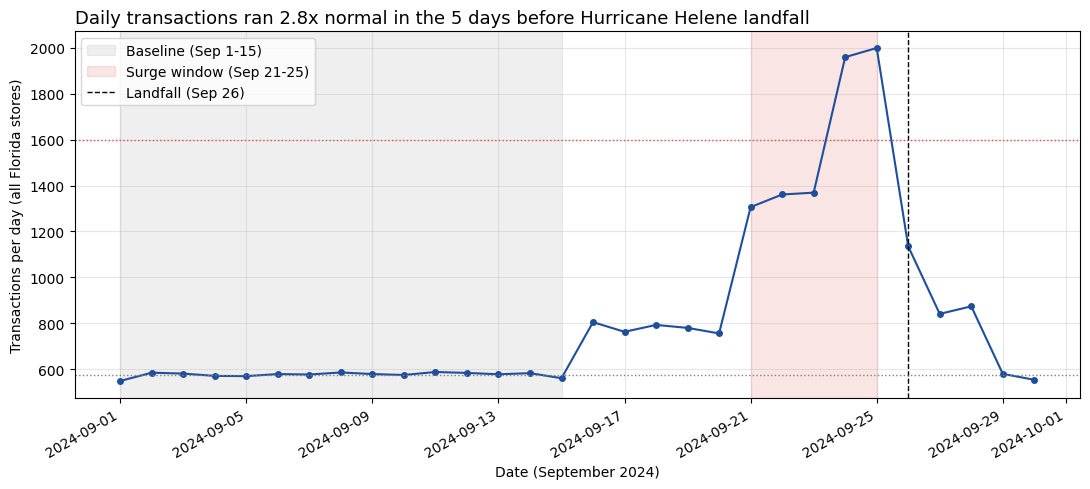

In [ ]:
# TODO: the chart

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(daily.index, daily["transactions"], marker="o", markersize=4, color="#1f4e9c")

ax.axvspan(pd.Timestamp(BASELINE[0]), pd.Timestamp(BASELINE[1]), color="gray", alpha=0.12, label="Baseline (Sep 1-15)")
ax.axvspan(pd.Timestamp(SURGE[0]), pd.Timestamp(SURGE[1]), color="#d9534f", alpha=0.15, label="Surge window (Sep 21-25)")
ax.axvline(LANDFALL, color="black", linestyle="--", linewidth=1, label="Landfall (Sep 26)")
ax.axhline(base["transactions"].mean(), color="gray", linestyle=":", linewidth=1)
ax.axhline(surge["transactions"].mean(), color="#d9534f", linestyle=":", linewidth=1)

mult = summary.loc["transactions", "multiple"]
ax.set_title(f"Daily transactions ran {mult:.1f}x normal in the 5 days before Hurricane Helene landfall",
             fontsize=13, loc="left")
ax.set_xlabel("Date (September 2024)")
ax.set_ylabel("Transactions per day (all Florida stores)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** Between Sep 21 and 25 in 2024 (five days before Hurricane Helene’s landfall), Florida stores averaged 1,599 transactions a day which is 2.8 times the 576-a-day average of the Sep 1 to 15 baseline. The surge peaked at 3.5 times normal on Sep 25 (the day before landfall).

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [ ]:
# TODO
# Q2 -- SKU consolidation
import pandas as pd



tx = pd.read_csv('data/walmart_transactions.csv', dtype=str)  # adjust path if needed
tx['quantity'] = pd.to_numeric(tx['quantity'], errors='coerce')
tx['unit_price'] = tx['unit_price'].astype(str).str.replace('$', '', regex=False).str.strip().astype(float)
tx = tx[tx['quantity'] > 0].copy()   # sales only, same rows the team's clean_orders uses
tx['revenue'] = tx['quantity'] * tx['unit_price']

sku_count_before = tx['sku'].nunique()
product_name_count_before = tx['product_name'].nunique()

# Built by hand from tx[['sku','product_name']].drop_duplicates() --
# sku is the stable key; product_name is spelled 2-6 different ways per sku.
CANON = {
    'PT-12': 'Pop-Tarts Strawberry', 'SKU#459812': 'Pop-Tarts Strawberry',
    'POPTART-STRAW': 'Pop-Tarts Strawberry', 'PT_STRAWBERRY': 'Pop-Tarts Strawberry',
    'WTR-24': 'Bottled Water 24-Pack', 'WATER24PK': 'Bottled Water 24-Pack', 'WTR_24PK': 'Bottled Water 24-Pack',
    'BATT-100': 'AA Batteries 4-Pack', 'BAT-AA4': 'AA Batteries 4-Pack', 'BATT_AA_4PK': 'AA Batteries 4-Pack',
    'FLASH-01': 'Flashlight LED', 'LED-FLASH': 'Flashlight LED',
    'BEER-24': 'Light Beer 24-Pack', 'LTBEER24': 'Light Beer 24-Pack',
    'BG-MONO': 'Monopoly Board Game', 'MONOPOLY-01': 'Monopoly Board Game', 'GAME-MONO': 'Monopoly Board Game',
    'CARDS-01': 'Playing Cards', 'PLAYCARD-STD': 'Playing Cards',
    'STREAM-01': 'Roku Streaming Stick', 'ROKU-STD': 'Roku Streaming Stick',
    'SOUP-CAN': 'Canned Soup', 'CNSOUP-01': 'Canned Soup',
    'BREAD-WH': 'White Bread', 'WHITEBREAD': 'White Bread',
    'PB-16': 'Peanut Butter', 'PNUTBTR-16': 'Peanut Butter',
    'CNDL-EM': 'Emergency Candles', 'CANDLE-EMRG': 'Emergency Candles',
    'FAID-01': 'First-Aid Kit', 'FIRSTAID-KIT': 'First-Aid Kit',
    'CHRG-PORT': 'Portable Phone Charger', 'PORTCHARGER': 'Portable Phone Charger',
    'CHIPS-VP': 'Chips Variety Pack', 'CHIPVARIETY': 'Chips Variety Pack',
    'PTOWEL-6': 'Paper Towels 6-Pack', 'PAPERTOWEL6': 'Paper Towels 6-Pack',
    'TP-12': 'Toilet Paper 12-Pack', 'TOILETPAPER12': 'Toilet Paper 12-Pack',
    'DIAP-S3': 'Diapers Size 3', 'DIAPERS-3': 'Diapers Size 3',
    'BFORM-01': 'Infant Formula', 'BABYFORMULA': 'Infant Formula',
    'TARP-HD': 'Heavy Duty Tarp', 'HDTARP-01': 'Heavy Duty Tarp',
}
tx['canonical_product'] = tx['sku'].map(CANON).fillna(tx['sku'])
canonical_count = tx['canonical_product'].nunique()

# before/after: largest consolidated family
sku_per_product = tx.groupby('canonical_product')['sku'].nunique().sort_values(ascending=False)
largest_family = sku_per_product.index[0]
fam = tx[tx['canonical_product'] == largest_family]
fragmented = fam.groupby('sku')['revenue'].sum().sort_values(ascending=False)
consolidated_total = fragmented.sum()

# assertion: consolidation must not change total units sold, only group them
assert tx['quantity'].sum() == tx.groupby('canonical_product')['quantity'].sum().sum()

print(f"started with {sku_count_before} sku codes / {product_name_count_before} product_name spellings")
print(f"ended with {canonical_count} canonical products")
print(f"largest family: '{largest_family}' from {sku_per_product.iloc[0]} sku codes")
print(fragmented.round(2))
print(f"consolidated total: ${consolidated_total:,.2f} ({consolidated_total/fragmented.iloc[0]:.1f}x its biggest single sku)")
print(f"total units unchanged by consolidation: {int(tx['quantity'].sum()):,} units, before == after")

started with 45 sku codes / 63 product_name spellings
ended with 20 canonical products
largest family: 'Pop-Tarts Strawberry' from 4 sku codes
sku
PT-12            4811.34
POPTART-STRAW    4539.93
PT_STRAWBERRY    4403.09
SKU#459812       4378.85
Name: revenue, dtype: float64
consolidated total: $18,133.21 (3.8x its biggest single sku)
total units unchanged by consolidation: 49,643 units, before == after


**Q2 answer:** 45 sku codes and 63 product_name spellings collapse to 20 real products; Pop-Tarts Strawberry alone was split across 4 sku codes, so its true revenue ($18,133.21) is 3.8x what any single sku code would have shown on its own.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [ ]:
# TODO
stores = pd.read_csv("data/store_locations.csv", dtype=str)
print(stores.columns.tolist())
display(stores.head())
print(tx.columns.tolist())
display(tx.head())
# Convert timestamps into proper datetime values
tx["timestamp"] = pd.to_datetime(
    tx["timestamp"],
    errors="coerce"
)


# Standardize store IDs in both datasets
tx["store_id"] = tx["store_id"].astype(str).str.strip().str.upper()

stores["store_id"] = (
    stores["store_id"].astype(str).str.strip().str.upper()
)

# Convert mixed timestamp formats to datetime
tx["timestamp"] = pd.to_datetime(
    tx["timestamp"],
    format="mixed",
    errors="coerce"
)

# Report timestamp issues
print("Missing/invalid timestamps:", tx["timestamp"].isna().sum())

print("Earliest transaction:", tx["timestamp"].min())
print("Latest transaction:", tx["timestamp"].max())

# Check store IDs against the reference file
transaction_stores = set(tx["store_id"].dropna().unique())
reference_stores = set(stores["store_id"].dropna().unique())

print("\nStores in transactions:", len(transaction_stores))
print("Stores in reference file:", len(reference_stores))

print("Unmatched transaction store IDs:",
      transaction_stores - reference_stores)

print("Stores with no transactions:",
      reference_stores - transaction_stores)

['store_id', 'store_name', 'city', 'state', 'zip_code', 'latitude', 'longitude', 'region']


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.292,-81.4076,Central


['transaction_id', 'store_id', 'timestamp', 'sku', 'product_name', 'category', 'quantity', 'unit_price', 'revenue', 'canonical_product']


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,revenue,canonical_product
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,3.15,Peanut Butter
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,2.02,Canned Soup
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,20.94,Toilet Paper 12-Pack
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,28.59,Roku Streaming Stick
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,56.46,Light Beer 24-Pack


Missing/invalid timestamps: 22930
Earliest transaction: 2024-09-01 06:03:10
Latest transaction: 2024-09-30 21:50:07

Stores in transactions: 36
Stores in reference file: 14
Unmatched transaction store IDs: {'FL078', 'FL330', 'FL501', 'FL_710', 'FL_302', 'FL_105', 'FL445', 'FL619', 'FL_078', 'FL105', 'FL_156', 'FL710', 'FL302', 'FL_445', 'FL156', 'FL_330', 'FL_501', 'FL_619', 'FL412', 'FL287', 'FL_412', 'FL_239'}
Stores with no transactions: set()


In [ ]:
raw_tx = pd.read_csv("data/walmart_transactions.csv", dtype=str)

print("Original timestamp examples:")
print(raw_tx["timestamp"].head(20).to_list())

print("\nTimestamp format counts:")
print(raw_tx["timestamp"].value_counts(dropna=False).head(15))

print("\nOriginal missing timestamps:")
print(raw_tx["timestamp"].isna().sum())
# Convert timestamps while allowing mixed formats
raw_tx["timestamp_clean"] = pd.to_datetime(
    raw_tx["timestamp"].str.strip(),
    format="mixed",
    errors="coerce"
)

print("Valid timestamps:",
      raw_tx["timestamp_clean"].notna().sum())

print("Invalid timestamps:",
      raw_tx["timestamp_clean"].isna().sum())

display(
    raw_tx.loc[
        raw_tx["timestamp_clean"].isna(),
        ["timestamp"]
    ].head(15)
)

# Standardize store IDs
def clean_store_id(series):
    return (
        series.astype("string")
        .str.strip()
        .str.upper()
        .str.replace("_", "-", regex=False)
        .str.replace(r"^FL(\d+)$", r"FL-\1", regex=True)
    )

raw_tx["store_id"] = clean_store_id(raw_tx["store_id"])
stores["store_id"] = clean_store_id(stores["store_id"])

# Check store ID consistency
transaction_stores = set(raw_tx["store_id"].dropna())
reference_stores = set(stores["store_id"].dropna())

print("Unmatched transaction stores:",
      transaction_stores - reference_stores)

print("Stores without transactions:",
      reference_stores - transaction_stores)

# Standardize store IDs
def clean_store_id(series):
    return (
        series.astype("string")
        .str.strip()
        .str.upper()
        .str.replace("_", "-", regex=False)
        .str.replace(r"^FL(\d+)$", r"FL-\1", regex=True)
    )

raw_tx["store_id"] = clean_store_id(raw_tx["store_id"])
stores["store_id"] = clean_store_id(stores["store_id"])

# Check store ID consistency
transaction_stores = set(raw_tx["store_id"].dropna())
reference_stores = set(stores["store_id"].dropna())

print("Unmatched transaction stores:",
      transaction_stores - reference_stores)

print("Stores without transactions:",
      reference_stores - transaction_stores)


Original timestamp examples:
['2024-09-24T09:48:13', '2024-09-13 20:30:20', '2024-09-17 10:06:00', '2024-09-11 06:29:08', '2024-09-26 15:59:42', '2024-09-23 10:32:34', '09/26/2024 09:26', '09/22/2024 14:47', '2024-09-08 16:40:14', '09/24/2024 20:03', '2024-09-07 17:22:06', '09-23-2024 18:24:47', '09/20/2024 13:19', '2024-09-26 08:24:01', '2024-09-18 08:12:08', '2024-09-10 11:49:33', '2024-09-06 14:52:50', '2024-09-20 07:43:43', '09-21-2024 11:40:38', '09/23/2024 13:17']

Timestamp format counts:
timestamp
NaN                  886
09/24/2024 21:09       5
22-Sep-2024 11:50      3
09/11/2024 11:42       3
09/24/2024 07:26       3
09/25/2024 08:20       3
09/24/2024 20:33       3
21-Sep-2024 15:48      3
09/25/2024 14:34       3
09/24/2024 07:31       3
28-Sep-2024 20:16      3
09/26/2024 07:41       3
09/25/2024 16:39       3
13-Sep-2024 16:55      3
09/23/2024 11:43       3
Name: count, dtype: int64

Original missing timestamps:
886
Valid timestamps: 24676
Invalid timestamps: 886


,timestamp
24,NaN
45,NaN
46,NaN
83,NaN
138,NaN
146,NaN
147,NaN
174,NaN
207,NaN
225,NaN


Unmatched transaction stores: set()
Stores without transactions: set()
Unmatched transaction stores: set()
Stores without transactions: set()


In [ ]:
# Convert the original timestamp strings using mixed-format parsing
raw_tx["timestamp_clean"] = pd.to_datetime(
    raw_tx["timestamp"].astype("string").str.strip(),
    format="mixed",
    errors="coerce"
)

# Create a date column for matching to daily weather
raw_tx["date"] = raw_tx["timestamp_clean"].dt.normalize()

# Convert sales columns to numeric
raw_tx["quantity"] = pd.to_numeric(raw_tx["quantity"], errors="coerce")
raw_tx["unit_price"] = pd.to_numeric(raw_tx["unit_price"], errors="coerce")

# Recalculate revenue consistently
raw_tx["revenue"] = raw_tx["quantity"] * raw_tx["unit_price"]

# Select the Orlando store
orlando = raw_tx[raw_tx["store_id"] == "FL-239"].copy()

print("Orlando transaction rows:", len(orlando))
print("Orlando transactions with valid timestamps:",
      orlando["timestamp_clean"].notna().sum())
print("Orlando transactions missing timestamps:",
      orlando["timestamp_clean"].isna().sum())

print("Orlando date range:",
      orlando["date"].min(), "to", orlando["date"].max())

Orlando transaction rows: 2103
Orlando transactions with valid timestamps: 2028
Orlando transactions missing timestamps: 75
Orlando date range: 2024-09-01 00:00:00 to 2024-09-30 00:00:00


In [ ]:

import pandas as pd
import requests
import time

# Open-Meteo historical weather API
BASE = "https://archive-api.open-meteo.com/v1/archive"

# HTTP errors that we should retry
RETRY_STATUSES = {429, 500, 502, 503, 504}


def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    """
    Download daily historical weather data from Open-Meteo.

    Returns:
        A DataFrame with date, precipitation_sum,
        windspeed_10m_max, and source columns.
    """

    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": "precipitation_sum,windspeed_10m_max",
        "timezone": "America/New_York"
    }

    # Retry the request if a temporary error occurs
    for attempt in range(1, tries + 1):
        try:
            response = requests.get(
                BASE,
                params=params,
                timeout=10
            )

        except (requests.Timeout, requests.ConnectionError):
            # Retry connection errors and timeouts
            if attempt == tries:
                raise

            time.sleep(2 ** attempt)
            continue

        # Retry rate limits and temporary server errors
        if response.status_code in RETRY_STATUSES:
            if attempt == tries:
                response.raise_for_status()

            time.sleep(2 ** attempt)
            continue

        # Raise any other unsuccessful HTTP response
        response.raise_for_status()

        # Convert the API response to a DataFrame
        data = pd.DataFrame(response.json()["daily"])

        # Rename time and convert it to datetime immediately
        data = data.rename(columns={"time": "date"})
        data["date"] = pd.to_datetime(data["date"])

        # Identify the source of the weather data
        data["source"] = "open-meteo"

        return data



# Get historical weather for the full month of September 2024
try:
    weather = daily_weather(
        start="2024-09-01",
        end="2024-09-30"
    )

    print("Weather API call successful!")
    print("Number of weather rows:", len(weather))
    print("Source:", weather["source"].iloc[0])
    print("Date column type:", weather["date"].dtype)
    print("Weather timezone: America/New_York")
    display(weather.head())

except requests.RequestException as err:
    print("Weather API call failed:", err)
    print("Check your internet connection and try again.")


Weather API call successful!
Number of weather rows: 30
Source: open-meteo
Date column type: datetime64[ns]
Weather timezone: America/New_York


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.9,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,23.1,15.2,open-meteo


In [ ]:
# Get Orlando's coordinates from the store reference file
orlando_location = stores[stores["store_id"] == "FL-239"].iloc[0]

latitude = orlando_location["latitude"]
longitude = orlando_location["longitude"]

# Retrieve historical weather for September 2024
weather = daily_weather(
    start="2024-09-01",
    end="2024-09-30",
    lat=latitude,
    lon=longitude
)

print("Weather rows:", len(weather))
print("Weather source:", weather["source"].unique())
print(weather.head())



Weather rows: 30
Weather source: ['open-meteo']
        date  precipitation_sum  windspeed_10m_max      source
0 2024-09-01                6.4               18.7  open-meteo
1 2024-09-02               22.0               12.7  open-meteo
2 2024-09-03               32.7               20.6  open-meteo
3 2024-09-04               21.2               12.6  open-meteo
4 2024-09-05               20.8               15.2  open-meteo


In [ ]:
# Join each transaction to its corresponding daily weather
sales_weather = orlando.merge(
    weather,
    on="date",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Check that the join did not multiply or remove transaction rows
print("Transaction rows before join:", len(orlando))
print("Transaction rows after join:", len(sales_weather))

print("\nJoin results:")
print(sales_weather["_merge"].value_counts())

# Verify that every original transaction is retained
assert len(sales_weather) == len(orlando)

# Count transactions that successfully matched weather
print("\nTransactions matched to weather:",
      (sales_weather["_merge"] == "both").sum())

print("Transactions without a weather match:",
      (sales_weather["_merge"] == "left_only").sum())

# Aggregate Orlando sales into daily totals
daily_sales = (
    orlando.dropna(subset=["date"])
    .groupby("date")
    .agg(
        daily_revenue=("revenue", "sum"),
        daily_quantity=("quantity", "sum"),
        transaction_count=("transaction_id", "count")
    )
    .reset_index()
)

# Join daily sales to daily weather
daily_analysis = daily_sales.merge(
    weather,
    on="date",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Daily sales observations:", len(daily_sales))
print("Daily observations after weather join:", len(daily_analysis))
print("\nDaily join results:")
print(daily_analysis["_merge"].value_counts())

# Verify that the daily join preserved all sales dates
assert len(daily_analysis) == len(daily_sales)

Transaction rows before join: 2103
Transaction rows after join: 2103

Join results:
_merge
both          2028
left_only       75
right_only       0
Name: count, dtype: int64

Transactions matched to weather: 2028
Transactions without a weather match: 75
Daily sales observations: 30
Daily observations after weather join: 30

Daily join results:
_merge
both          30
left_only      0
right_only     0
Name: count, dtype: int64


                   daily_revenue  daily_quantity  precipitation_sum  \
daily_revenue              1.000           0.988             -0.274   
daily_quantity             0.988           1.000             -0.255   
precipitation_sum         -0.274          -0.255              1.000   
windspeed_10m_max          0.427           0.450             -0.040   

                   windspeed_10m_max  
daily_revenue                  0.427  
daily_quantity                 0.450  
precipitation_sum             -0.040  
windspeed_10m_max              1.000  


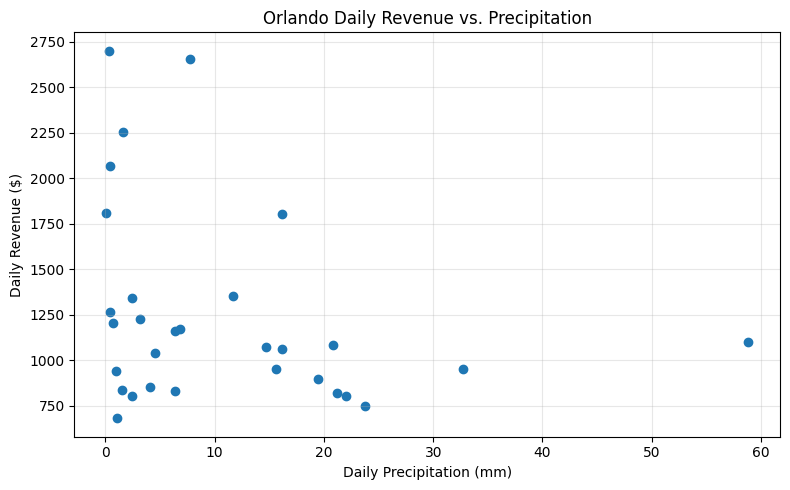

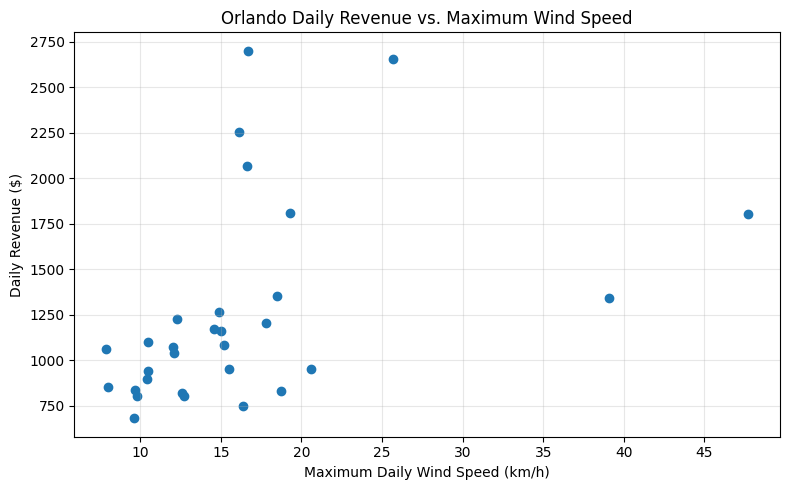

In [ ]:
# Calculate correlations between daily sales and weather variables
correlation_matrix = daily_analysis[
    [
        "daily_revenue",
        "daily_quantity",
        "precipitation_sum",
        "windspeed_10m_max"
    ]
].corr()

print(correlation_matrix.round(3))
import matplotlib.pyplot as plt

# Daily revenue vs. precipitation
plt.figure(figsize=(8, 5))
plt.scatter(
    daily_analysis["precipitation_sum"],
    daily_analysis["daily_revenue"]
)

plt.xlabel("Daily Precipitation (mm)")
plt.ylabel("Daily Revenue ($)")
plt.title("Orlando Daily Revenue vs. Precipitation")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Daily revenue vs. maximum wind speed
plt.figure(figsize=(8, 5))
plt.scatter(
    daily_analysis["windspeed_10m_max"],
    daily_analysis["daily_revenue"]
)

plt.xlabel("Maximum Daily Wind Speed (km/h)")
plt.ylabel("Daily Revenue ($)")
plt.title("Orlando Daily Revenue vs. Maximum Wind Speed")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** _..._ In Orlando (FL-239) during September 2024, daily revenue had a weak negative correlation with precipitation (r = -0.274) and a moderate positive correlation with maximum wind speed (r = 0.427), based on 30 daily observations. However, these are correlations, not causal relationships, and the results are limited to one Walmart store over one month.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _..._

**Q5 (signal or artifact):** _..._

### Self-check

In [ ]:
progress = {
    'q1_multiple': 2.77,            # TODO: a number
    'q1_baseline_window': 'Sep 1-15, 2024 (15 days); surge Sep 21-25 (5 days)',   # TODO: stated explicitly
    'q2_canonical_products': None,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': None,  # TODO: how many
    'notebook_runs_clean': False,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 2.77
PASS - q1_baseline_window = Sep 1-15, 2024 (15 days); surge Sep 21-25 (5 days)
FAIL - q2_canonical_products = None
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
FAIL - charts_with_message_titles = None
FAIL - notebook_runs_clean = False
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

_your answer here_